# 3 · Calibration to the 1978 boarding-school influenza outbreak

**Data.** In January 1978 influenza spread through a boarding school in the north of England. 512 of 763 boys fell ill. The dataset gives the daily number of boys confined to bed and convalescing from 22 January to 4 February. The index case was infected by 10 January and had a fever from 15 to 18 January.
- **Source:** Anonymous (1978), *British Medical Journal* 1:587, via the R package [`outbreaks`](https://github.com/reconverse/outbreaks) (MIT licence).
- **Access:** downloaded on first use (checksum-verified) and not redistributed.

**Model.** 763 agents in dormitory-like small-world contacts and a dining hall, starting from one index case on 10 January. The influenza course is:
- an optional latent period;
- a prodrome with cough and sneezing (infectious);
- a bed stage with high fever, muscle pain and cough, a β⁻ profile in which the boy is confined to the sick bay;
- convalescence with muscle pain, whose length comes from the report's recovery rule and is not fitted.

**Method.** Approximate Bayesian computation (rejection). 5,000 draws from uniform priors over 5 parameters are each simulated with 3 seeds, and the 100 draws closest to the in-bed counts are kept. Two adjustments handle the randomness of a single introduction:
- Each run is **aligned on its take-off**, the first day with ≥20 boys in bed, so shapes are compared. A deterministic SIR baseline gets the same freedom through its fitted start time.
- The posterior predictive is conditioned on a major outbreak, as observed.

Only the in-bed curve is fitted. **The convalescent curve and the number of boys who fell ill are held out.**

In [1]:
from IPython.display import Image, display
import pandas as pd

from epidemic_abm import pipeline

pd.set_option("display.precision", 4)
FIGURES = pipeline.FIGURES


def show(name):
    display(Image(filename=str(FIGURES / name)))
from epidemic_abm.data import load_boarding_school

observed = load_boarding_school()
observed

,date,in_bed,convalescent
1,1978-01-22,3,0
2,1978-01-23,8,0
3,1978-01-24,26,0
4,1978-01-25,76,0
5,1978-01-26,225,9
6,1978-01-27,298,17
7,1978-01-28,258,105
8,1978-01-29,233,162
9,1978-01-30,189,176
10,1978-01-31,128,166


In [2]:
calibration, sir = pipeline.calibration()   # ABC with 5,000 draws x 3 seeds (about 6 minutes on 8 cores)
pd.DataFrame({"agent-based model": {k: v for k, v in calibration.fit_metrics().items() if not isinstance(v, dict)},
              "SIR baseline": {"in_bed_rmse": round(sir["in_bed_rmse"], 2)}})

,agent-based model,SIR baseline
in_bed_rmse,16.350,16.01
in_bed_coverage_90,1.000,NaN
convalescent_rmse,48.110,NaN
convalescent_coverage_90,0.857,NaN
observed_take_off_day,14.000,NaN
fizzled_share,0.007,NaN


In [3]:
pd.DataFrame({k: v for k, v in calibration.fit_metrics().items() if isinstance(v, dict)}).T

,low,median,high
boys_ill,270.800,369.000,566.400
r_early,2.625,3.269,4.143
take_off_day,3.000,6.000,8.000


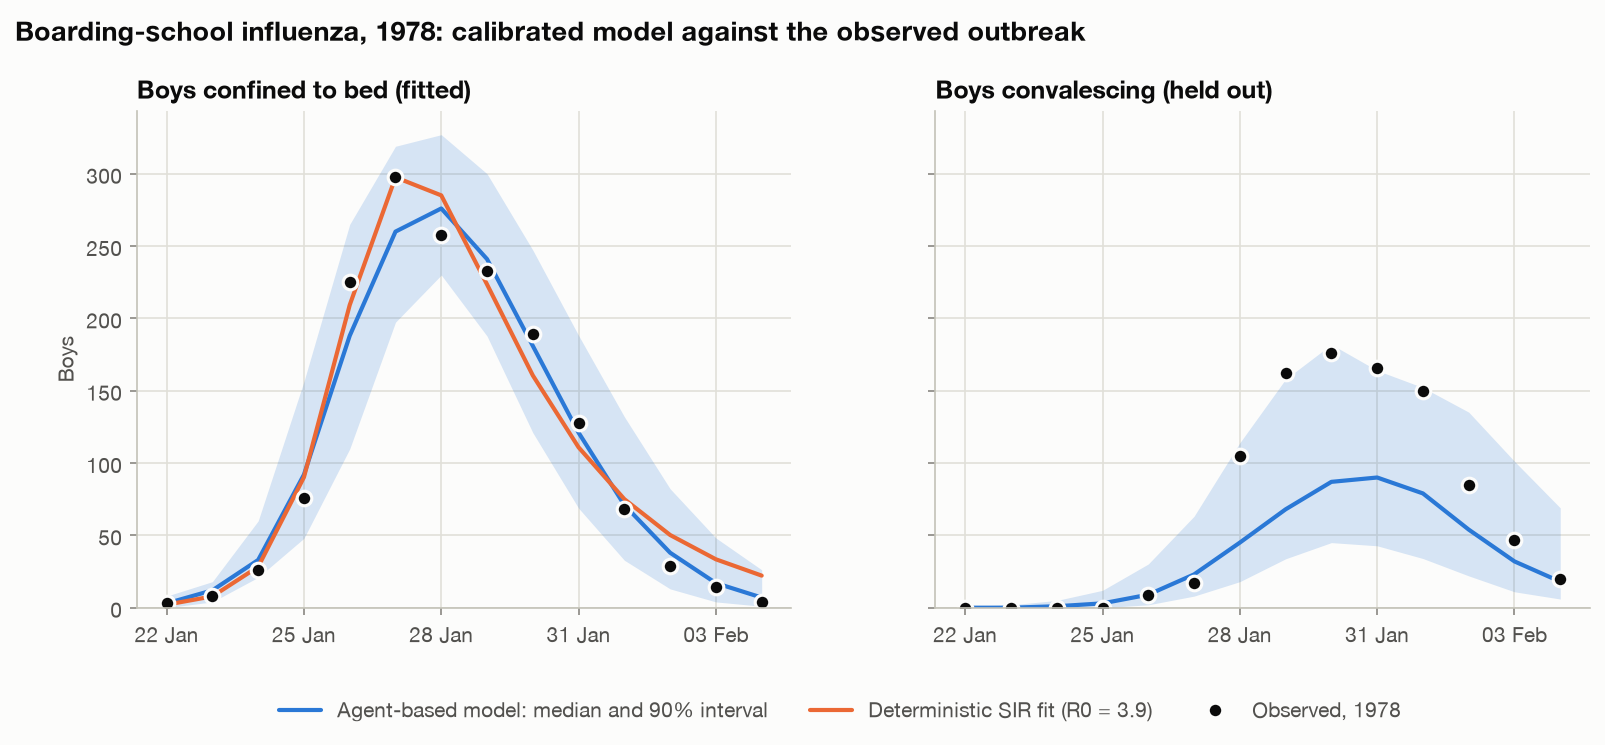

In [4]:
show("calibration_fit.png")

,low,median,high
beta_scale,4.101,8.249,11.399
latent_days,0.000,1.000,2.000
prodromal_days,1.000,2.000,3.000
bed_days,3.000,4.000,6.000
bed_probability,0.364,0.501,0.792


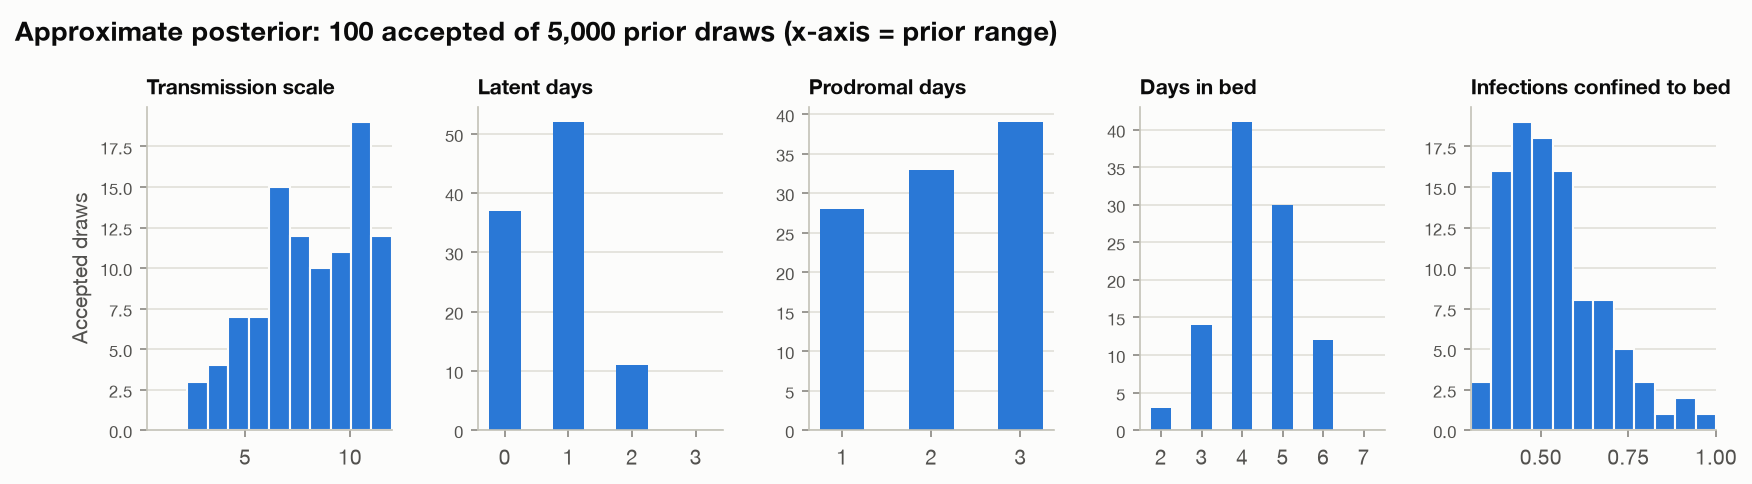

In [5]:
display(calibration.posterior().round(3))
show("calibration_posterior.png")

- **Fit to the in-bed curve:** the calibrated model matches it about as well as the classic SIR fit. RMSE is 16.4 vs 16.0 for SIR, and 100% of observations fall inside the 90% predictive band.
- **Held out — boys who fell ill:** the model predicts 369 (271–566), and the observed 512 lies inside this interval. A deterministic SIR model with the fitted R0 = 3.93 implies 747 of 763 boys infected. It can only match the observed 512 if many infections never confined a boy to bed, which the agent-based model represents explicitly: about 50% of infections led to bed rest.
- **Held out — convalescent curve:** the model underestimates it (RMSE 48.1, 86% of points inside the band, predicted peak 90 vs 176 observed). Under the report's recovery rule, boys recover within one or two days of leaving bed, while the data imply longer convalescence. This is a structural finding about the recovery mechanism, not a fitting problem.
- **Reproduction number:** the measured early R of the calibrated model is 3.27 (2.62–4.14), compared with 3.93 from SIR.
- **Take-off timing:** simulated outbreaks take off 6 (3–8) days after the index infection, against 14 days in 1978. The real first generation was slower than the model's. A single, possibly isolated index case or an initially smaller susceptible group could explain this, and the data cannot tell them apart.
- **Identifiability:**
  - Days in bed (4 (3–6)) and the share of infections confined to bed (0.50 (0.36–0.79)) are well identified.
  - The transmission scale is only bounded from below (8.2 (4.1–11.4), prior 0.3–12): above about 4.1 spread is limited by contacts and stage durations, not by per-contact transmission.